# 03 — Đánh giá: vòng 1 so với vòng 2

Chỉ **đọc** kết quả đã lưu (lịch sử train, file dự đoán) và chấm ở máy — không gọi GPU, không tốn tiền.

- Tập test chính thức: **230 câu sạch** (`test_vi_sach_v2.jsonl`) + **28 câu mơ hồ mới** (`test_vi_bo_sung.jsonl`),
  cả hai do người viết và đã đóng băng.
- Luật chấm **C** (mặc định) và luật cũ — xem PLAN.md mục G.
- Chênh lệch giữa hai vòng **chỉ đến từ dữ liệu**: cùng model gốc, cùng siêu tham số.

In [ ]:
import json, math, os, sys
from pathlib import Path
GOC = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(GOC); sys.path.insert(0, str(GOC))

import matplotlib.pyplot as plt
from eval.metrics import cham_toan_bo, cham_mot_cau, cau_sai, doc_output, nhom_cua_dap_an

MAU = {"Vòng 1": "#2a78d6", "Vòng 2": "#eb6834"}   # đã qua validate_palette.js
CHU_PHU = "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#d6d5d0",
    "axes.grid": True, "grid.color": "#ecebe7", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold"})

def doc(p):
    with open(p, encoding="utf-8") as f:
        return [json.loads(x) for x in f if x.strip()]
def du(p):
    return {r["prompt"]: r["output"] for r in doc(p)}

TEST = doc("data/processed/final/test_vi_sach_v2.jsonl")
MOI = doc("data/processed/final/test_vi_bo_sung.jsonl")
DD = {"Vòng 1": (du("runs/student-full/du_doan_test.jsonl"), du("runs/student-full/du_doan_test_vi_bo_sung.jsonl")),
      "Vòng 2": (du("runs/student-full-v2/du_doan_test_vi_sach_v2.jsonl"),
                 du("runs/student-full-v2/du_doan_test_vi_bo_sung.jsonl"))}
len(TEST), len(MOI)

(230, 28)

## 1. Quá trình train

Cả hai vòng: loss val thấp nhất quanh epoch 2 rồi nhích lên — dấu hiệu bắt đầu học thuộc. (Val của hai vòng là hai
tập khác nhau, chỉ so **hình dạng** đường cong, không so con số.)

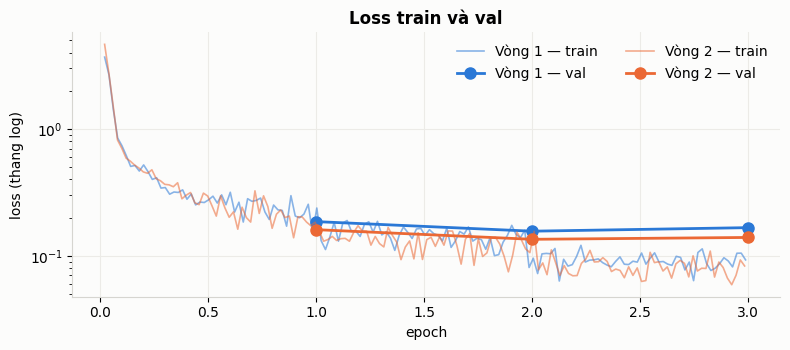

In [2]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for k, p in (("Vòng 1", "runs/student-full/trainer_state.json"), ("Vòng 2", "runs/student-full-v2/trainer_state.json")):
    ls = json.load(open(p, encoding="utf-8"))["log_history"]
    tr = [(x["epoch"], x["loss"]) for x in ls if "loss" in x]
    ev = [(x["epoch"], x["eval_loss"]) for x in ls if "eval_loss" in x]
    ax.plot(*zip(*tr), color=MAU[k], lw=1.2, alpha=0.55, label=f"{k} — train")
    ax.plot(*zip(*ev), color=MAU[k], lw=2, marker="o", ms=8, label=f"{k} — val")
ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("loss (thang log)")
ax.set_title("Loss train và val"); ax.legend(frameon=False, ncol=2)
plt.tight_layout(); plt.show()

## 2. Điểm trên 230 câu test sạch — theo nhóm, luật C

Không gộp một con số. Đường nét đứt là **ngưỡng đạt đã chốt trước** khi train.

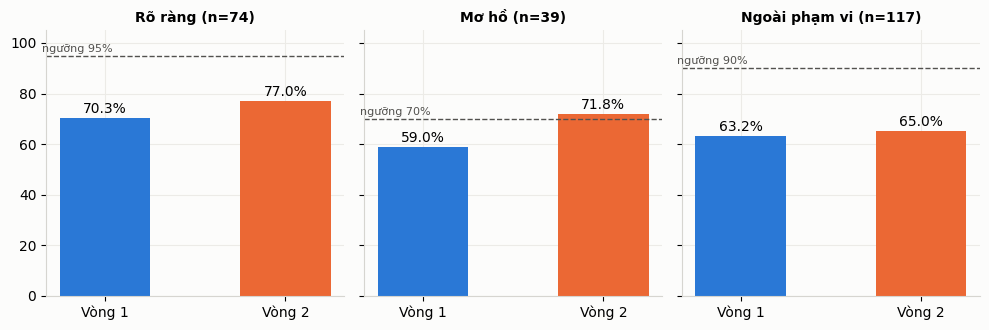

                         Vòng 1   Vòng 2
Rõ ràng (luật cũ)         66.2%    73.0%
Rõ ràng (luật C)          70.3%    77.0%
Mơ hồ (luật cũ)           46.2%    64.1%
Mơ hồ (luật C)            59.0%    71.8%
Ngoài phạm vi (luật cũ)    63.2%    65.0%
Ngoài phạm vi (luật C)    63.2%    65.0%
lỗi goi_bua               18.7%    17.8%
lỗi tu_choi_nham           0.0%     0.0%
lỗi hoi_lai_thua           4.3%     3.9%


In [3]:
NHOM = [("ro_rang", "Rõ ràng", 95), ("mo_ho", "Mơ hồ", 70), ("ngoai_pham_vi", "Ngoài phạm vi", 90)]
BC = {k: cham_toan_bo(TEST, v[0], "C") for k, v in DD.items()}
BC_CU = {k: cham_toan_bo(TEST, v[0], "cu") for k, v in DD.items()}
fig, axs = plt.subplots(1, 3, figsize=(10, 3.4), sharey=True)
for ax, (khoa, ten, nguong) in zip(axs, NHOM):
    gt = [BC[k]["theo_nhom"][khoa]["dung_%"] for k in DD]
    ax.bar(list(DD), gt, color=[MAU[k] for k in DD], width=0.5)
    for i, g in enumerate(gt):
        ax.text(i, g + 2, f"{g:.1f}%", ha="center")
    ax.axhline(nguong, color=CHU_PHU, lw=1, ls="--"); ax.text(-0.35, nguong + 1.5, f"ngưỡng {nguong}%", fontsize=8, color=CHU_PHU, ha="left")
    ax.set_title(f"{ten} (n={BC['Vòng 1']['theo_nhom'][khoa]['so_cau']})", fontsize=10); ax.set_ylim(0, 105)
plt.tight_layout(); plt.show()

print(f"{'':22}{'Vòng 1':>9}{'Vòng 2':>9}")
for khoa, ten, _ in NHOM:
    for luat, B in (("cũ", BC_CU), ("C", BC)):
        print(f"{ten + ' (luật ' + luat + ')':22}{B['Vòng 1']['theo_nhom'][khoa]['dung_%']:>8.1f}%{B['Vòng 2']['theo_nhom'][khoa]['dung_%']:>8.1f}%")
for k in ("goi_bua", "tu_choi_nham", "hoi_lai_thua"):
    print(f"{'lỗi ' + k:22}{BC['Vòng 1']['ty_le_loi_%'][k]:>8.1f}%{BC['Vòng 2']['ty_le_loi_%'][k]:>8.1f}%")

## 3. Tăng có thật không? — kiểm định McNemar

Hai model chấm trên **cùng** bộ câu → đếm câu đổi từ sai→đúng và đúng→sai. p < 0,05 mới coi là chắc chắn.

In [4]:
def mcnemar(b, c):
    n = b + c
    return 1.0 if n == 0 else min(1.0, 2 * sum(math.comb(n, i) for i in range(min(b, c) + 1)) / 2**n)

for ten, T, i in (("230 câu sạch", TEST, 0), ("28 câu mới", MOI, 1)):
    dem = {}
    for r in T:
        a = cham_mot_cau(DD["Vòng 1"][i][r["prompt"]], r["completion"])[0] == "dung"
        b = cham_mot_cau(DD["Vòng 2"][i][r["prompt"]], r["completion"])[0] == "dung"
        for g in (nhom_cua_dap_an(doc_output(r["completion"])), "TỔNG"):
            x = dem.setdefault(g, [0, 0]); x[0] += (not a and b); x[1] += (a and not b)
    for g, (len_, xuong) in sorted(dem.items()):
        print(f"{ten:13} {g:14} sai→đúng {len_:>3} | đúng→sai {xuong:>3} | p = {mcnemar(len_, xuong):.3f}")

230 câu sạch  TỔNG           sai→đúng  23 | đúng→sai  11 | p = 0.058
230 câu sạch  mo_ho          sai→đúng   6 | đúng→sai   1 | p = 0.125
230 câu sạch  ngoai_pham_vi  sai→đúng  11 | đúng→sai   9 | p = 0.824
230 câu sạch  ro_rang        sai→đúng   6 | đúng→sai   1 | p = 0.125
28 câu mới    TỔNG           sai→đúng  11 | đúng→sai   0 | p = 0.001
28 câu mới    mo_ho          sai→đúng  11 | đúng→sai   0 | p = 0.001


## 4. 28 câu mơ hồ mới — 7 hàm vừa bổ sung dữ liệu

Viết bởi người thứ hai, chưa từng xuất hiện khi train. Đây là thước đo trực tiếp cho việc sinh thêm mẫu hỏi lại.

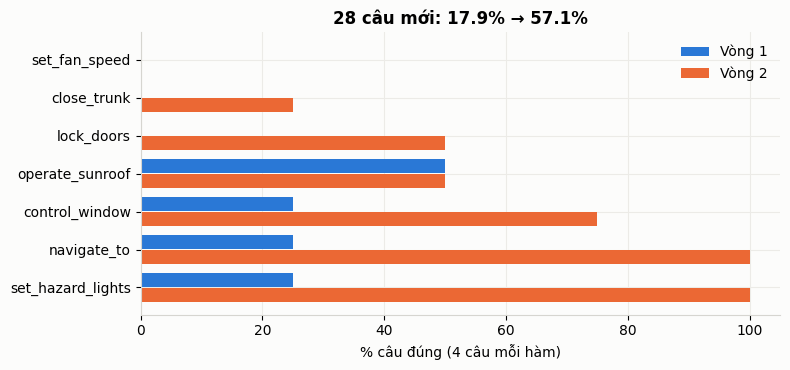

In [5]:
B2 = {k: cham_toan_bo(MOI, v[1], "C") for k, v in DD.items()}
ham = sorted(B2["Vòng 1"]["theo_ham"], key=lambda h: B2["Vòng 2"]["theo_ham"][h]["dung_%"])
fig, ax = plt.subplots(figsize=(8, 3.8))
y = range(len(ham))
for i, k in enumerate(DD):
    ax.barh([j + (-0.2 if i == 0 else 0.2) for j in y], [B2[k]["theo_ham"][h]["dung_%"] for h in ham],
            height=0.36, color=MAU[k], label=k)
ax.set_yticks(list(y)); ax.set_yticklabels(ham); ax.invert_yaxis(); ax.set_xlim(0, 105)
ax.set_xlabel("% câu đúng (4 câu mỗi hàm)")
ax.set_title(f"28 câu mới: {B2['Vòng 1']['theo_nhom']['mo_ho']['dung_%']}% → {B2['Vòng 2']['theo_nhom']['mo_ho']['dung_%']}%")
ax.legend(frameon=False, loc="upper right"); plt.tight_layout(); plt.show()

## 5. Kiểu sai — vòng 2 sửa được gì, không sửa được gì

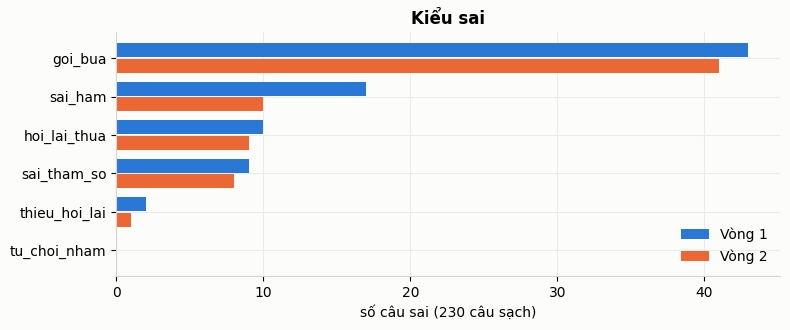

In [6]:
kieu = ["goi_bua", "sai_ham", "hoi_lai_thua", "sai_tham_so", "thieu_hoi_lai", "tu_choi_nham"]
fig, ax = plt.subplots(figsize=(8, 3.4))
y = range(len(kieu))
for i, k in enumerate(DD):
    ax.barh([j + (-0.2 if i == 0 else 0.2) for j in y], [BC[k]["loi_theo_kieu"].get(t, 0) for t in kieu],
            height=0.36, color=MAU[k], label=k)
ax.set_yticks(list(y)); ax.set_yticklabels(kieu); ax.invert_yaxis()
ax.set_xlabel("số câu sai (230 câu sạch)"); ax.set_title("Kiểu sai"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

**Đọc biểu đồ:** `sai_ham` giảm rõ (khoá từ vựng "kính" đã sửa). `goi_bua` gần như **không đổi** — 1.667 câu từ
chối dạng mệnh lệnh không chuyển được sang câu người thật (trên val cùng nguồn sinh, gọi bừa chỉ 0,2%).

## 6. Câu “kính” — lỗi khoá từ vựng của vòng 1

In [7]:
from gen.records import query_from_call_prompt as q
for T, i in ((TEST, 0), (MOI, 1)):
    for r in T:
        c = q(r["prompt"])
        if "kính" in c.lower() and "sấy" not in c.lower():
            v1 = DD["Vòng 1"][i][r["prompt"]]; v2 = DD["Vòng 2"][i][r["prompt"]]
            print(f"{c[:42]:44} v1: {v1[:30]:32} v2: {v2[:30]}")

Hạ kính ghế phụ xuống một nửa                v1: <nexa_8>(state="down", zone="p   v2: <nexa_15>(window="front_right"
Hạ hết bốn kính cửa sổ xuống                 v1: <nexa_15>(window="all", positi   v2: <nexa_15>(window="all", positi
Hạ hé kính bên phụ khoảng 20%                v1: <nexa_8>(state="down", intensi   v2: <nexa_15>(window="front_right"
Kéo hết kính xe lên rồi khóa cửa             v1: <nexa_ask><nexa_8>(state="on")   v2: <nexa_ask><nexa_15>(window="al
Kính lái mờ tịt chẳng nhìn thấy gì           v1: <nexa_ask><nexa_8>(state="on")   v2: <nexa_ask><nexa_8>(state="on")
Kính sau đọng hơi nước hết rồi               v1: <nexa_ask><nexa_8>(state="on",   v2: <nexa_ask><nexa_8>(state="on",
Sương bám đầy kính chẳng thấy đường          v1: <nexa_ask><nexa_8>(state="on")   v2: <nexa_ask><nexa_8>(state="on")
Hạ kính chắn gió xuống cho thoáng            v1: <nexa_8>(state="down")<nexa_en   v2: <nexa_15>(window="front_left",
Có anh bảo vệ đang gõ gõ vào kính phía tôi   v1: <nexa_ask><nexa

## 7. Câu vòng 2 còn sai (230 câu sạch) — để chẩn đoán vòng sau

Nhớ nguyên tắc: **không vá theo câu test** — dùng danh sách này để hiểu kiểu lỗi, còn sửa thì dựa trên dữ liệu train/val.

In [8]:
from collections import Counter
ds = cau_sai(TEST, DD["Vòng 2"][0])
print(Counter(x["kieu_sai"] for x in ds))
for x in ds:
    if x["kieu_sai"] != "goi_bua":
        print(f"[{x['kieu_sai']:13}] {x['cau'][:40]:42} cần {x['dap_an'][:34]:36} ra {x['model_sinh'][:34]}")

Counter({'goi_bua': 41, 'sai_ham': 10, 'hoi_lai_thua': 9, 'sai_tham_so': 8, 'thieu_hoi_lai': 1})
[sai_ham      ] Xe đang sạc pin đúng không                 cần <nexa_1>()<nexa_end>                 ra <nexa_3>()<nexa_end>
[sai_tham_so  ] Hạ nhiệt độ cabin xuống mát nhất có thể    cần <nexa_6>(state="on", temperature=1   ra <nexa_6>(state="on")<nexa_end>
[sai_ham      ] Giảm gió điều hòa xuống mức 1              cần <nexa_7>(level=1)<nexa_end>          ra <nexa_6>(state="on", temperature=1
[hoi_lai_thua ] Kéo hết kính xe lên rồi khóa cửa           cần <nexa_15>(window="all", position="   ra <nexa_ask><nexa_15>(window="all", 
[sai_tham_so  ] Tăng âm lượng lên xíu                      cần <nexa_19>(delta=2)<nexa_end>         ra <nexa_19>(delta=10)<nexa_end>
[sai_tham_so  ] Vặn nhỏ loa xuống mức 5                    cần <nexa_19>(set_value=5)<nexa_end>     ra <nexa_19>(delta=-5)<nexa_end>
[sai_tham_so  ] Mở kênh VOV Giao thông                     cần <nexa_20>(source="radio", query="V   ra 